# Cat and Dog Image Classifier

Solution for the freeCodeCamp *Machine Learning with Python* project.

A MobileNetV2 base pre-trained on ImageNet is used as a feature extractor, followed by a small classifier head. The top 30 layers are then fine-tuned. Horizontal-flip test-time augmentation is applied on the 50 test images.

Target: at least 63% of the test images correctly classified.

In [1]:
try:
    %tensorflow_version 2.x
except Exception:
    pass
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Dense, Conv2D, Flatten, Dropout,
                                     MaxPooling2D, GlobalAveragePooling2D)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import os
import numpy as np
import matplotlib.pyplot as plt
tf.random.set_seed(42)
np.random.seed(42)

In [2]:
# Get project files (skipped when the data is already present locally).
if not os.path.isdir('data/cats_and_dogs'):
    if not os.path.exists('cats_and_dogs'):
        !wget -q https://cdn.freecodecamp.org/project-data/cats-and-dogs/cats_and_dogs.zip
        !unzip -q -o cats_and_dogs.zip
    PATH = 'cats_and_dogs'
else:
    PATH = 'data/cats_and_dogs'

train_dir = os.path.join(PATH, 'train')
validation_dir = os.path.join(PATH, 'validation')
test_dir = os.path.join(PATH, 'test')

total_train = sum([len(files) for r, d, files in os.walk(train_dir)])
total_val = sum([len(files) for r, d, files in os.walk(validation_dir)])
total_test = len([f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

batch_size = 32
epochs = 8
IMG_HEIGHT = 150
IMG_WIDTH = 150
print(total_train, total_val, total_test)

2001 1001 50


In [3]:
# 3
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

train_image_generator = ImageDataGenerator(preprocessing_function=preprocess_input)
validation_image_generator = ImageDataGenerator(preprocessing_function=preprocess_input)
test_image_generator = ImageDataGenerator(preprocessing_function=preprocess_input)

train_data_gen = train_image_generator.flow_from_directory(
    batch_size=batch_size, directory=train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH), class_mode='binary', seed=42)

val_data_gen = validation_image_generator.flow_from_directory(
    batch_size=batch_size, directory=validation_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH), class_mode='binary', seed=42)

test_data_gen = test_image_generator.flow_from_directory(
    batch_size=1, directory=PATH, classes=['test'],
    target_size=(IMG_HEIGHT, IMG_WIDTH), class_mode=None, shuffle=False)

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 50 images belonging to 1 classes.


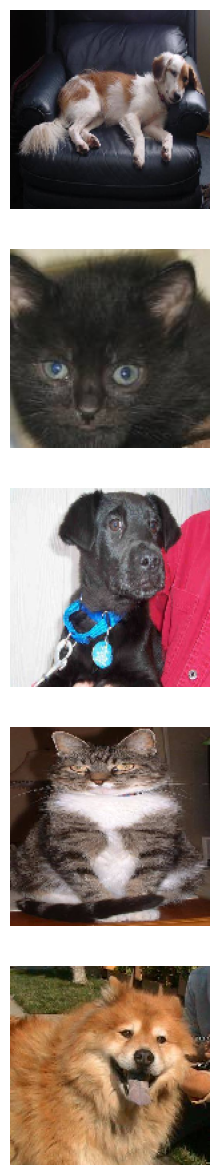

In [4]:
# 4
def plotImages(images_arr, probabilities=False):
    fig, axes = plt.subplots(len(images_arr), 1, figsize=(5, len(images_arr) * 3))
    if probabilities is False:
        for img, ax in zip(images_arr, axes):
            ax.imshow(np.clip(img * 0.5 + 0.5, 0, 1) if img.min() < 0 else img)
            ax.axis('off')
    else:
        for img, probability, ax in zip(images_arr, probabilities, axes):
            ax.imshow(np.clip(img * 0.5 + 0.5, 0, 1) if img.min() < 0 else img)
            ax.axis('off')
            if probability > 0.5:
                ax.set_title('%.2f' % (probability * 100) + '% dog')
            else:
                ax.set_title('%.2f' % ((1 - probability) * 100) + '% cat')
    plt.show()

sample_training_images, _ = next(train_data_gen)
plotImages(sample_training_images[:5])

In [5]:
# 5 - data augmentation
train_image_generator = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest')

Found 2000 images belonging to 2 classes.


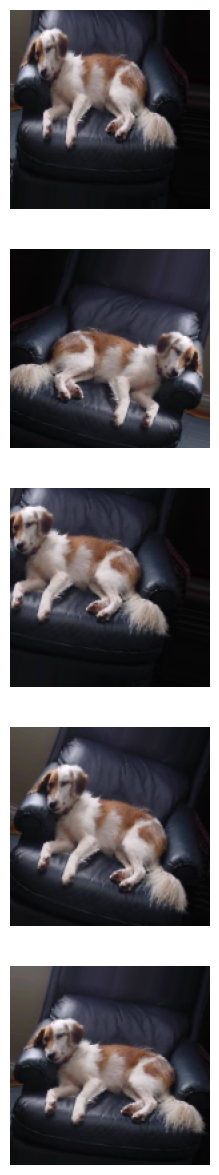

In [6]:
# 6
train_data_gen = train_image_generator.flow_from_directory(
    batch_size=batch_size, directory=train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH), class_mode='binary', seed=42)

augmented_images = [train_data_gen[0][0][0] for i in range(5)]
plotImages(augmented_images)

In [7]:
# 7 - MobileNetV2 base + classifier head
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), include_top=False, weights='imagenet')
base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(1, activation='sigmoid'),
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

/tmp/ipykernel_3666/4190318051.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
# 8 - stage 1: train the head with the base frozen
history = model.fit(
    train_data_gen,
    steps_per_epoch=total_train // batch_size,
    epochs=epochs,
    validation_data=val_data_gen,
    validation_steps=total_val // batch_size,
    callbacks=[EarlyStopping(monitor='val_accuracy', patience=3,
                             restore_best_weights=True, verbose=1)],
    verbose=2)

Epoch 1/8


2026-11-07 14:28:41.976647: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 23040000 exceeds 10% of free system memory.
2026-11-07 14:28:42.053390: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 23040000 exceeds 10% of free system memory.
2026-11-07 14:28:42.154925: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 69120000 exceeds 10% of free system memory.


2026-11-07 14:28:42.241276: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 72855552 exceeds 10% of free system memory.
2026-11-07 14:28:42.321928: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 17743872 exceeds 10% of free system memory.


62/62 - 103s - 2s/step - accuracy: 0.8730 - loss: 0.2891 - val_accuracy: 0.9496 - val_loss: 0.1242


Epoch 2/8


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


... (11 outputs left out)

Epoch 8/8


62/62 - 22s - 352ms/step - accuracy: 1.0000 - loss: 0.0274 - val_accuracy: 0.9607 - val_loss: 0.1088


Epoch 8: early stopping


Restoring model weights from the end of the best epoch: 5.


In [9]:
# 8b - stage 2: fine-tune the top 30 layers of MobileNetV2
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(
    train_data_gen,
    steps_per_epoch=total_train // batch_size,
    epochs=8,
    validation_data=val_data_gen,
    validation_steps=total_val // batch_size,
    callbacks=[EarlyStopping(monitor='val_accuracy', patience=3,
                             restore_best_weights=True, verbose=1),
               ReduceLROnPlateau(monitor='val_accuracy', factor=0.5,
                                 patience=1, min_lr=1e-7, verbose=1)],
    verbose=2)

Epoch 1/8


62/62 - 280s - 5s/step - accuracy: 0.9451 - loss: 0.1217 - val_accuracy: 0.9688 - val_loss: 0.0883 - learning_rate: 1.0000e-05


Epoch 2/8



Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.


62/62 - 24s - 387ms/step - accuracy: 0.9688 - loss: 0.0987 - val_accuracy: 0.9688 - val_loss: 0.0897 - learning_rate: 1.0000e-05


Epoch 3/8


... (10 outputs left out)


Epoch 7: ReduceLROnPlateau reducing learning rate to 6.24999984211172e-07.


62/62 - 80s - 1s/step - accuracy: 0.9588 - loss: 0.0947 - val_accuracy: 0.9698 - val_loss: 0.0838 - learning_rate: 1.2500e-06


Epoch 7: early stopping


Restoring model weights from the end of the best epoch: 4.


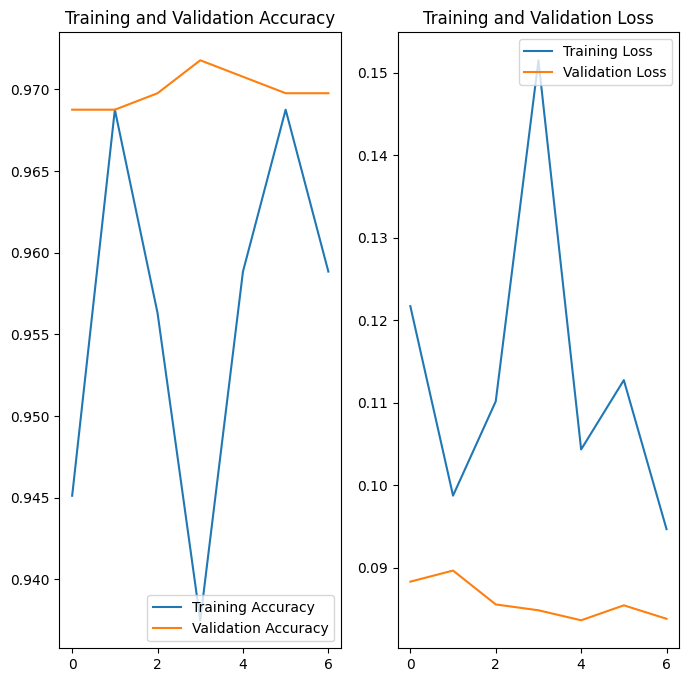

In [10]:
# 9
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [11]:
# 10 - predictions on the 50 test images (with horizontal-flip TTA)
test_data_gen.reset()
test_images = []
for i in range(len(test_data_gen)):
    test_images.append(test_data_gen[i])  # batch (1, H, W, 3)
test_images = np.vstack(test_images)
flipped = np.ascontiguousarray(test_images[:, :, ::-1, :])
probabilities = (model.predict(test_images, verbose=0).flatten()
                 + model.predict(flipped, verbose=0).flatten()) / 2.0
print(probabilities.shape)

(50,)


In [12]:
# 11 - DO NOT MODIFY CONTENTS
answers = [1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
           1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
           1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1,
           1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1,
           0, 0, 0, 0, 0, 0]

correct = 0
for probability, answer in zip(probabilities, answers):
    if round(probability) == answer:
        correct += 1

percentage_identified = (correct / len(answers)) * 100
passed_challenge = percentage_identified >= 63

print(f'Your model correctly identified {round(percentage_identified, 2)}% of the images of cats and dogs.')
if passed_challenge:
    print('You passed the challenge!')
else:
    print("You haven't passed yet. Your model should identify at least 63% of the images. Keep trying. You will get it!")

Your model correctly identified 96.0% of the images of cats and dogs.
You passed the challenge!
